# Exploratory Data Analysis: Developer Survey

Part of my IBM Data Analyst Capstone project. In this notebook I explore the cleaned Stack Overflow developer survey to answer questions about job satisfaction, remote work, programming language usage by country, and education.

Where respondents skipped a question, I leave the answer missing and exclude them from that analysis rather than filling the gaps with made-up values.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [1]:
# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Set pandas option to display all columns
pd.set_option('display.max_columns', None)

# Display the first few rows of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,EmbeddedHaveWorkedWith,EmbeddedWantToWorkWith,EmbeddedAdmired,MiscTechHaveWorkedWith,MiscTechWantToWorkWith,MiscTechAdmired,ToolsTechHaveWorkedWith,ToolsTechWantToWorkWith,ToolsTechAdmired,NEWCollabToolsHaveWorkedWith,NEWCollabToolsWantToWorkWith,NEWCollabToolsAdmired,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackSyncHaveWorkedWith,OfficeStackSyncWantToWorkWith,OfficeStackSyncAdmired,AISearchDevHaveWorkedWith,AISearchDevWantToWorkWith,AISearchDevAdmired,NEWSOSites,SOVisitFreq,SOAccount,SOPartFreq,SOHow,SOComm,AISelect,AISent,AIBen,AIAcc,AIComplex,AIToolCurrently Using,AIToolInterested in Using,AIToolNot interested in Using,AINextMuch more integrated,AINextNo change,AINextMore integrated,AINextLess integrated,AINextMuch less integrated,AIThreat,AIEthics,AIChallenges,TBranch,ICorPM,WorkExp,Knowledge_1,Knowledge_2,Knowledge_3,Knowledge_4,Knowledge_5,Knowledge_6,Knowledge_7,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I have never visited Stack Overflow or the Sta...,NaN,NaN,NaN,NaN,NaN,Yes,Very favorable,Increase productivity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Dynamodb;MongoDB;PostgreSQL,PostgreSQL,PostgreSQL,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Express;Next.js;Node.js;React,Express;Htmx;Node.js;React;Remix,Express;Node.js;React,NaN,NaN,NaN,NaN,NaN,NaN,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,MacOS;Windows,MacOS,NaN,NaN,NaN,Microsoft Teams;Slack,Slack,Slack,NaN,NaN,NaN,Stack Overflow for Teams (private knowledge sh...,Multiple times per day,Yes,Multiple times per day,Quickly finding code solutions;Finding reliabl...,"Yes, definitely","No, and I don't plan to",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes,Individual contributor,17.0,Agree,Disagree,Agree,Agree,Agree,Neither agree nor disa

## 2. Check missing data in key columns
`Employment` is complete. `JobSat` and `RemoteWork` have many gaps.

In [ ]:
print(df.shape)

cols = ['Employment', 'JobSat', 'RemoteWork']
missing = df[cols].isnull().sum()
print(missing)
print((missing / len(df) * 100).round(1))

More than half of respondents skipped `JobSat`, and about 16% skipped `RemoteWork`. Filling those with the median or most frequent value would invent answers. For example, filling `JobSat` with the median gives every experience group the same median of 7, which hides any real difference. I leave them missing and each analysis below uses only respondents who answered.

## 3. Experience and job satisfaction
Convert `YearsCodePro` to numbers, group it into experience ranges, and compare median job satisfaction.

In [ ]:
df['YearsCodePro'] = df['YearsCodePro'].replace({'Less than 1 year': 0.5, 'More than 50 years': 51})
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')
print(df['YearsCodePro'].describe())

In [ ]:
bins = [-1, 5, 10, 20, float('inf')]
labels = ['0-5', '5-10', '10-20', '>20']
df['ExpRange'] = pd.cut(df['YearsCodePro'], bins=bins, labels=labels)

# Respondents with no JobSat answer are ignored automatically
median_sat = df.groupby('ExpRange', observed=True)['JobSat'].median()
print(median_sat)

median_sat.plot(kind='bar', color='steelblue')
plt.title('Median Job Satisfaction by Years of Professional Coding Experience')
plt.xlabel('Experience range (years)')
plt.ylabel('Median JobSat')
plt.xticks(rotation=0)
plt.show()

## 4. Distribution of job satisfaction

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(x='JobSat', data=df, color='steelblue')
plt.title('Distribution of Job Satisfaction (respondents who answered)')
plt.xlabel('JobSat')
plt.ylabel('Count')
plt.show()

## 5. Remote work by employment type and job role
`DevType` holds several roles per respondent, so I split it into one row per role. Employment type uses the first-listed type.

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x='RemoteWork', data=df, order=df['RemoteWork'].value_counts().index)
plt.title('Remote Work Distribution')
plt.show()

# By employment type (first listed type)
df['EmploymentMain'] = df['Employment'].str.split(';').str[0]
print(pd.crosstab(df['EmploymentMain'], df['RemoteWork']))

# By job role (DevType holds several roles separated by ';')
roles = (df[['DevType', 'RemoteWork']].dropna()
         .assign(DevType=lambda d: d['DevType'].str.split(';'))
         .explode('DevType'))
role_remote = pd.crosstab(roles['DevType'], roles['RemoteWork'])
print(role_remote)

role_pct = role_remote.div(role_remote.sum(axis=1), axis=0) * 100
role_pct.sort_values('Remote', ascending=False).plot(kind='barh', stacked=True, figsize=(10, 10))
plt.title('Remote Work Preference by Job Role (%)')
plt.show()

## 6. Programming languages by country
Share of respondents in the five countries with the most responses who have worked with each of the ten most-used languages.

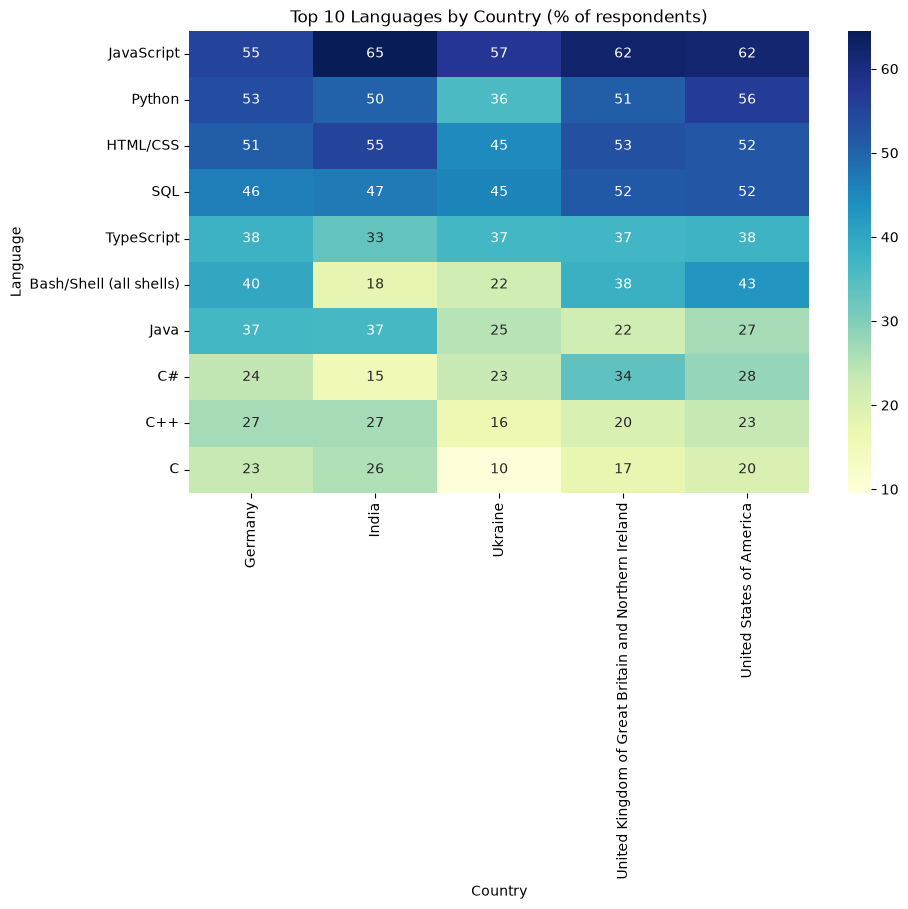

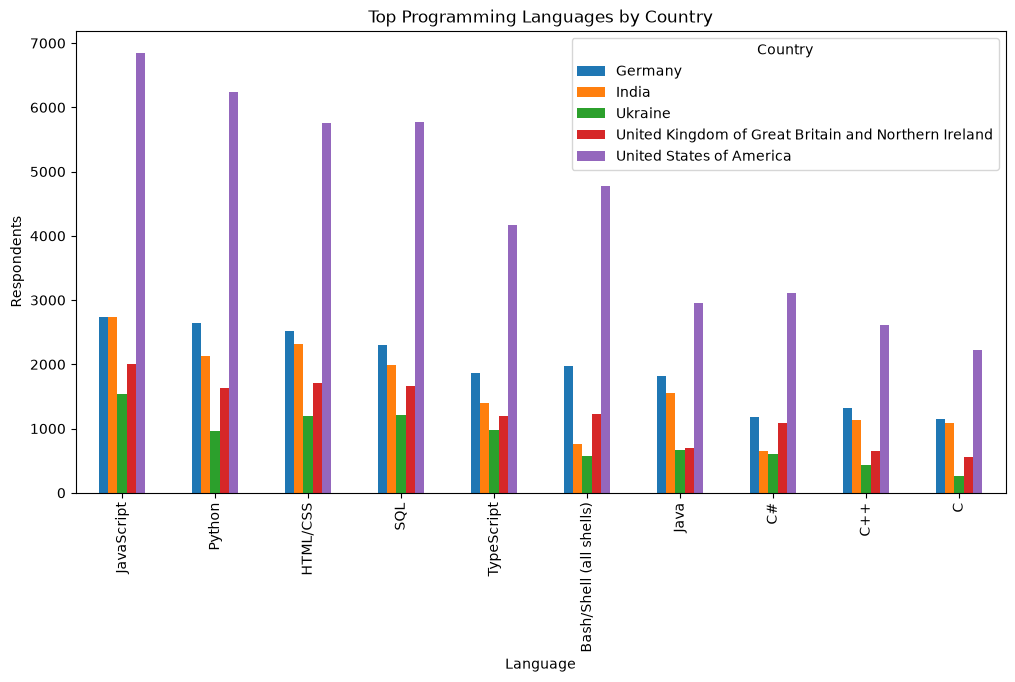

In [2]:
top_countries = df['Country'].value_counts().head(5).index
lang = df[['Country', 'LanguageHaveWorkedWith']].dropna()
lang = lang[lang['Country'].isin(top_countries)]
lang = (lang.assign(Language=lang['LanguageHaveWorkedWith'].str.split(';'))
            .explode('Language')
            .reset_index(drop=True))   # <-- fixes the duplicate index

counts = pd.crosstab(lang['Language'], lang['Country'])
top_langs = counts.sum(axis=1).nlargest(10).index
counts = counts.loc[top_langs]

# % of respondents per country
pct = counts.div(df[df['Country'].isin(top_countries)].groupby('Country').size(), axis=1) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(pct, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Top 10 Languages by Country (% of respondents)')
plt.show()

counts.plot(kind='bar', figsize=(12, 6))
plt.title('Top Programming Languages by Country')
plt.ylabel('Respondents')
plt.show()

## 7. Experience and satisfaction points

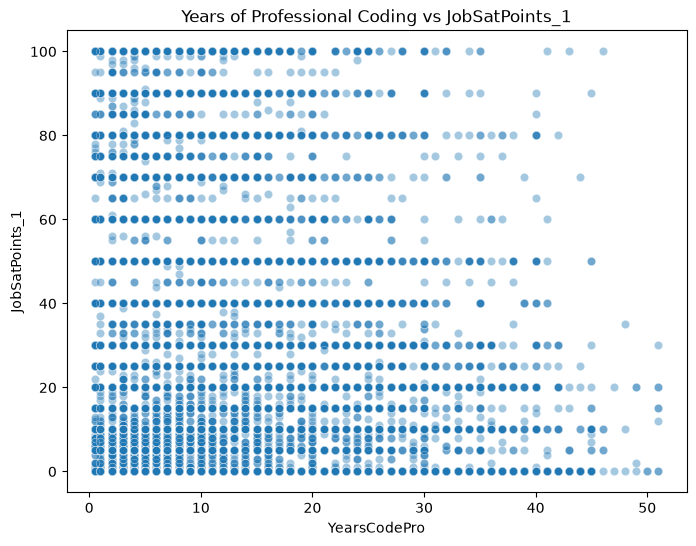

                YearsCodePro  JobSatPoints_1
YearsCodePro        1.000000       -0.028467
JobSatPoints_1     -0.028467        1.000000

In [3]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='YearsCodePro', y='JobSatPoints_1', data=df, alpha=0.4)
plt.title('Years of Professional Coding vs JobSatPoints_1')
plt.show()

print(df[['YearsCodePro', 'JobSatPoints_1']].corr())

The correlation between years of professional coding and `JobSatPoints_1` is about -0.03, which is practically no relationship.

## 8. Education level and employment type
Based on the first-listed employment type.

EmploymentMain                                      Employed, full-time  \
EdLevel                                                                   
Associate degree (A.A., A.S., etc.)                                1260   
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                      19136   
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                   12489   
Primary/elementary school                                           201   
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                     2312   
Secondary school (e.g. American high school, Ge...                 1860   
Some college/university study without earning a...                 4494   
Something else                                                      448   

EmploymentMain                                      Employed, part-time  \
EdLevel                                                                   
Associate degree (A.A., A.S., etc.)                                  39   
Bachelor’s degree (B.A.,

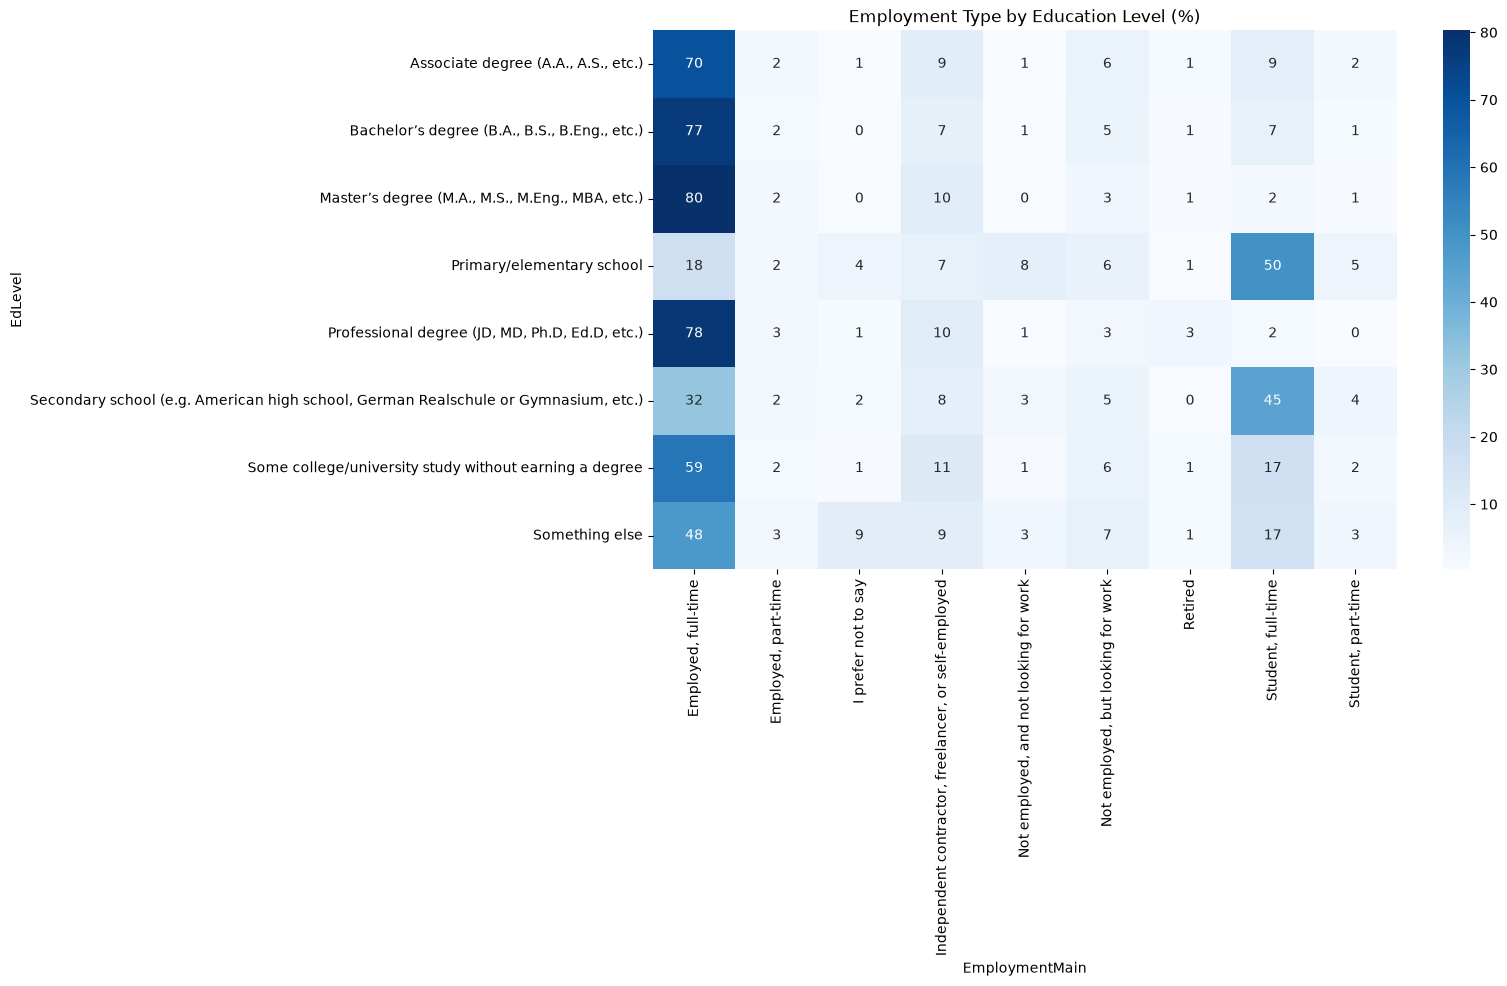

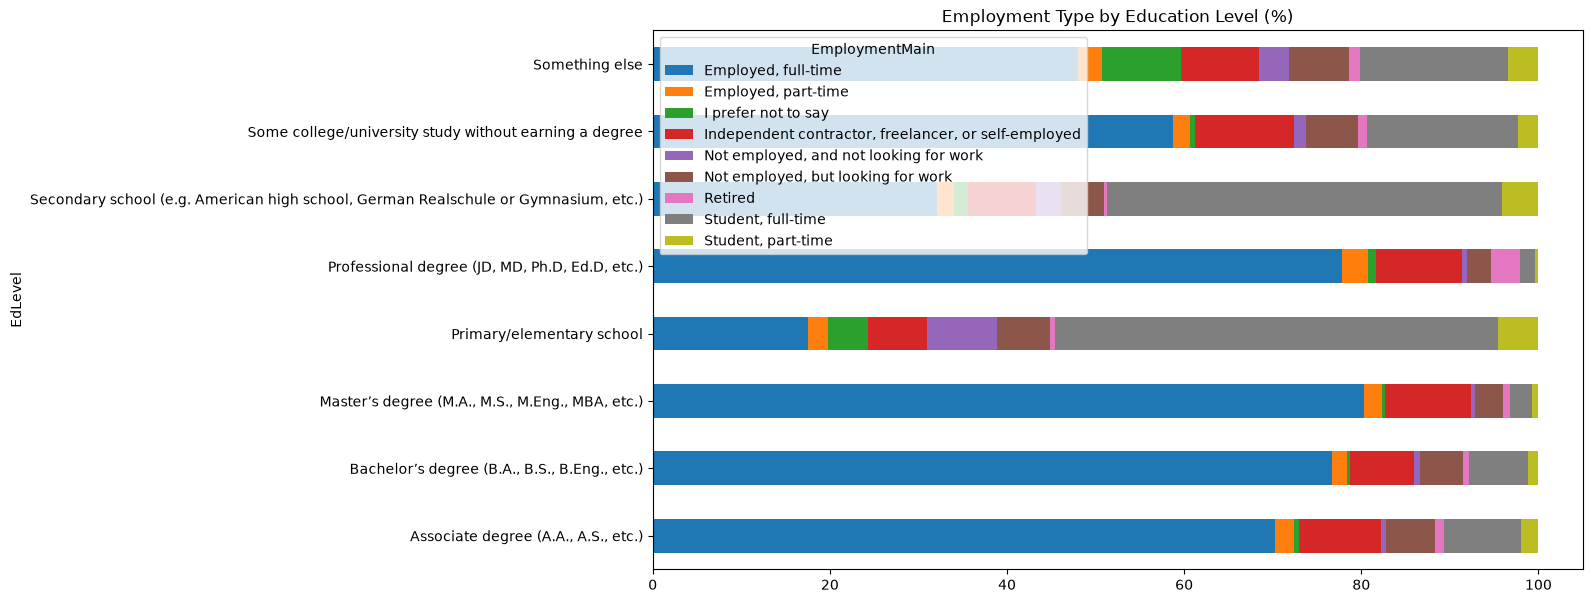

In [4]:
ct = pd.crosstab(df['EdLevel'], df['EmploymentMain'])
print(ct)

ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
plt.figure(figsize=(12, 7))
sns.heatmap(ct_pct, annot=True, fmt='.0f', cmap='Blues')
plt.title('Employment Type by Education Level (%)')
plt.show()

ct_pct.plot(kind='barh', stacked=True, figsize=(12, 7))
plt.title('Employment Type by Education Level (%)')
plt.show()